In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the faculty-provided dataset correctly
df = pd.read_csv('/content/Studentdata.csv', sep=';')

# Display dataset information
print("Dataset dimensions:", df.shape)

print("\nFirst five records:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nDuplicate records:", df.duplicated().sum())


Dataset dimensions: (4424, 37)

First five records:


,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate



Column names:
['Marital status', 'Application mode', 'Application order', 'Course', 'Daytime/evening attendance\t', 'Previous qualification', 'Previous qualification (grade)', 'Nacionality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation", 'Admission grade', 'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'Age at enrollment', 'International', 'Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)', 'Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)', 'Unemployment rate', 'Inflation rate', 'GDP', 'Targe

In [3]:

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.rename("Data Type").to_frame())

print("\nMissing values per column:")
display(df.isnull().sum().rename("Missing Values").to_frame())

print("\nTotal missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nTarget categories:")
print(df["Target"].value_counts(dropna=False))


Number of rows: 4424
Number of columns: 37

Column names:
['Marital status', 'Application mode', 'Application order', 'Course', 'Daytime/evening attendance\t', 'Previous qualification', 'Previous qualification (grade)', 'Nacionality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation", 'Admission grade', 'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'Age at enrollment', 'International', 'Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)', 'Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)', 'Unemploy

,Data Type
Marital status,int64
Application mode,int64
Application order,int64
Course,int64
Daytime/evening attendance\t,int64
Previous qualification,int64
Previous qualification (grade),float64
Nacionality,int64
Mother's qualification,int64
Father's qualification,int64



Missing values per column:


,Missing Values
Marital status,0
Application mode,0
Application order,0
Course,0
Daytime/evening attendance\t,0
Previous qualification,0
Previous qualification (grade),0
Nacionality,0
Mother's qualification,0
Father's qualification,0



Total missing values: 0
Duplicate rows: 0

Target categories:
Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64


In [6]:
# Clean column names by removing leading/trailing whitespace and tabs
df.columns = (
    df.columns
    .str.replace('\t', '', regex=False)
    .str.strip()
)

# Verify the cleaned column name
print([col for col in df.columns if "attendance" in col.lower()])

['Daytime/evening attendance']


In [7]:
listed_cols = set(binary_cols + categorical_cols + numerical_cols)

print("Unclassified columns:", set(df.columns) - listed_cols - {"Target"})
print("Columns not found:", listed_cols - set(df.columns))

Unclassified columns: {'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (without evaluations)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (credited)'}
Columns not found: set()


In [8]:
# Check the target column
print("Target classes:")
print(df["Target"].value_counts())

# Remove rows with missing target values, if any
df = df.dropna(subset=["Target"]).copy()

# Remove duplicate rows, if any
df = df.drop_duplicates().copy()

print("\nDataset shape after cleaning:", df.shape)
print("\nMissing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Target classes:
Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64

Dataset shape after cleaning: (4424, 37)

Missing values: 0
Duplicate rows: 0


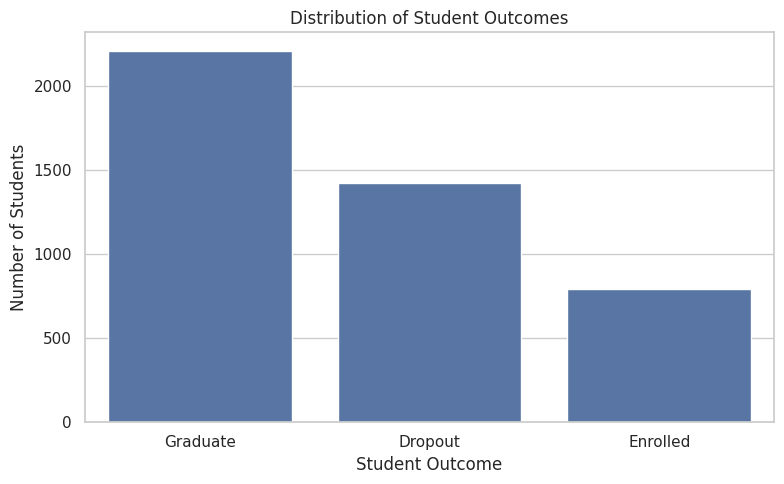


Target distribution (%):
Target
Graduate    49.93
Dropout     32.12
Enrolled    17.95
Name: proportion, dtype: float64


In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Target", order=df["Target"].value_counts().index)

plt.title("Distribution of Student Outcomes")
plt.xlabel("Student Outcome")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

print("\nTarget distribution (%):")
print((df["Target"].value_counts(normalize=True) * 100).round(2))

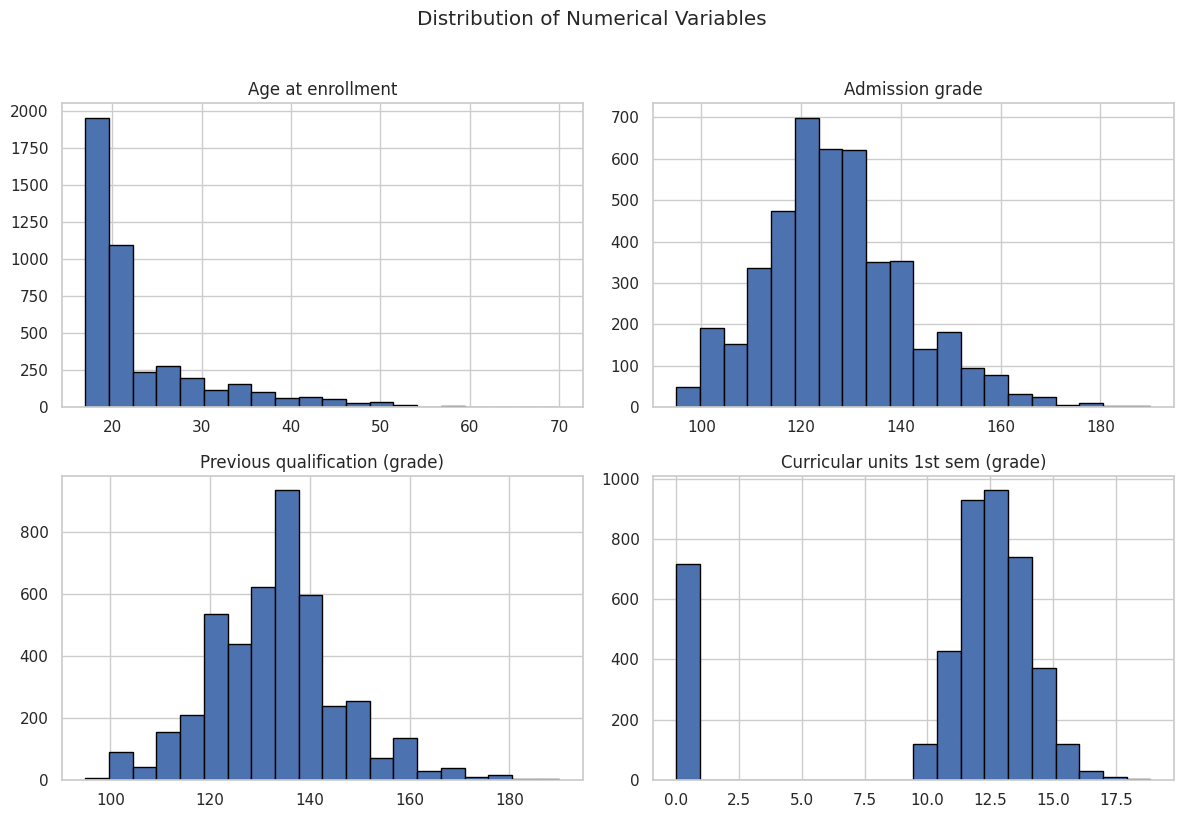

In [10]:

hist_cols = [
    "Age at enrollment",
    "Admission grade",
    "Previous qualification (grade)",
    "Curricular units 1st sem (grade)"
]

df[hist_cols].hist(
    figsize=(12, 8),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Variables", y=1.02)
plt.tight_layout()
plt.show()


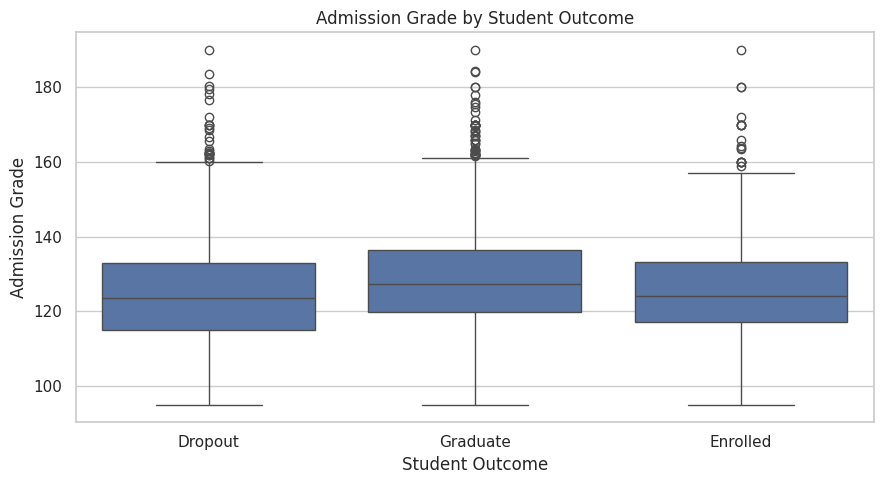

,count,mean,median,std
Target,,,,
Dropout,1421,124.96,123.6,15.13
Enrolled,794,125.53,124.1,13.79
Graduate,2209,128.79,127.4,14.07


In [11]:

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Target",
    y="Admission grade"
)

plt.title("Admission Grade by Student Outcome")
plt.xlabel("Student Outcome")
plt.ylabel("Admission Grade")
plt.tight_layout()
plt.show()

display(
    df.groupby("Target")["Admission grade"]
      .agg(["count", "mean", "median", "std"])
      .round(2)
)


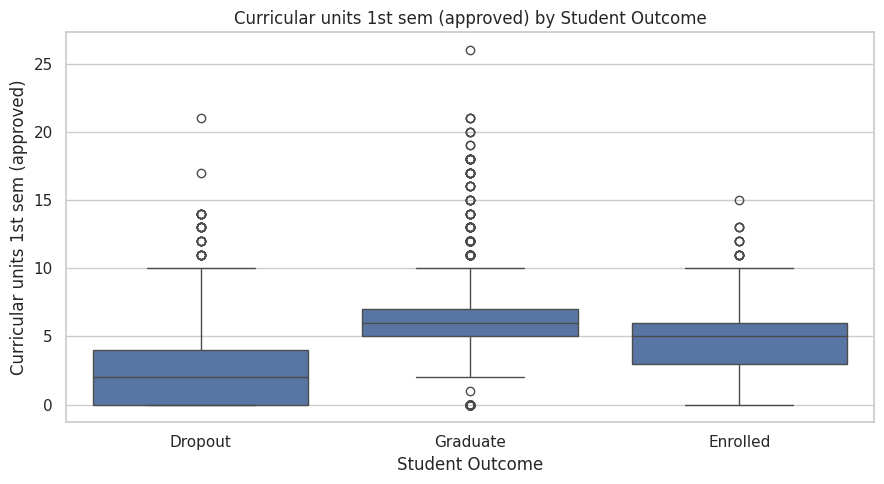

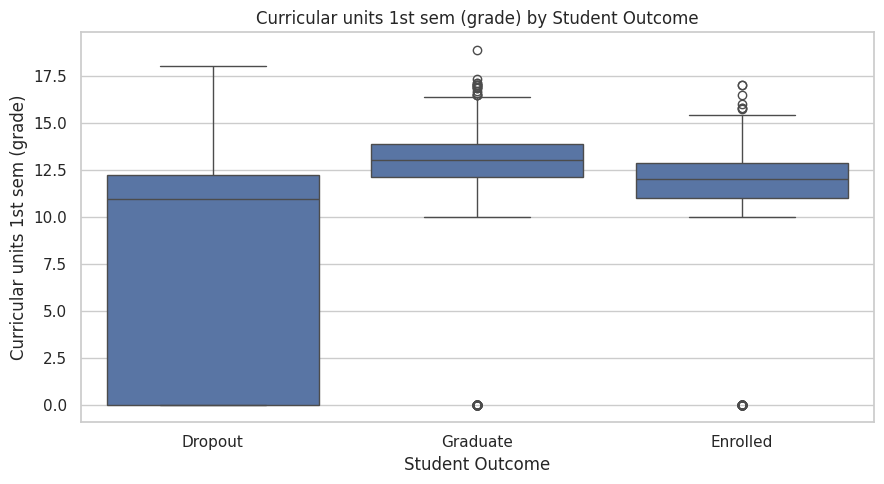

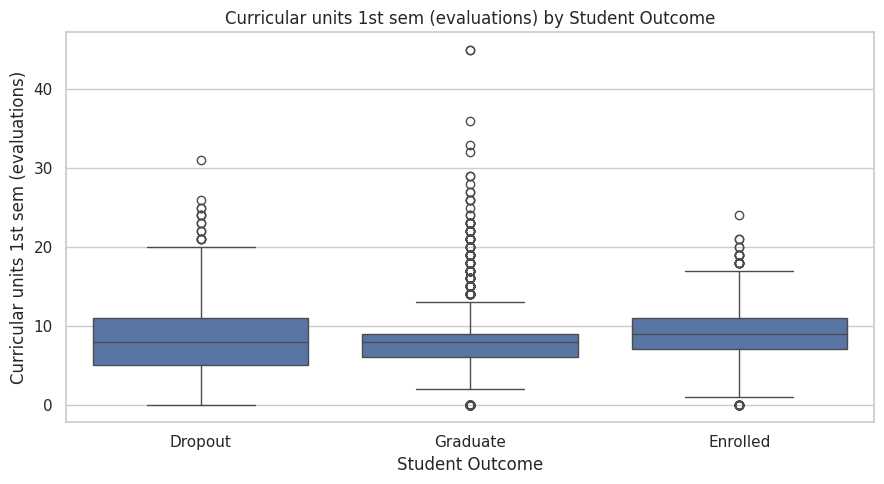

Average first-semester performance by outcome:


,Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (evaluations)
Target,,,
Dropout,2.55,7.26,7.75
Enrolled,4.32,11.13,9.34
Graduate,6.23,12.64,8.28


In [12]:

performance_cols = [
    "Curricular units 1st sem (approved)",
    "Curricular units 1st sem (grade)",
    "Curricular units 1st sem (evaluations)"
]

for col in performance_cols:
    plt.figure(figsize=(9, 5))

    sns.boxplot(
        data=df,
        x="Target",
        y=col
    )

    plt.title(f"{col} by Student Outcome")
    plt.xlabel("Student Outcome")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

print("Average first-semester performance by outcome:")
display(df.groupby("Target")[performance_cols].mean().round(2))


Target,Dropout,Enrolled,Graduate
Age group,,,
20 or younger,21.25,18.46,60.29
21–25,35.63,21.98,42.39
26–30,59.79,14.88,25.33
31–40,55.15,13.27,31.58
Above 40,50.67,11.56,37.78


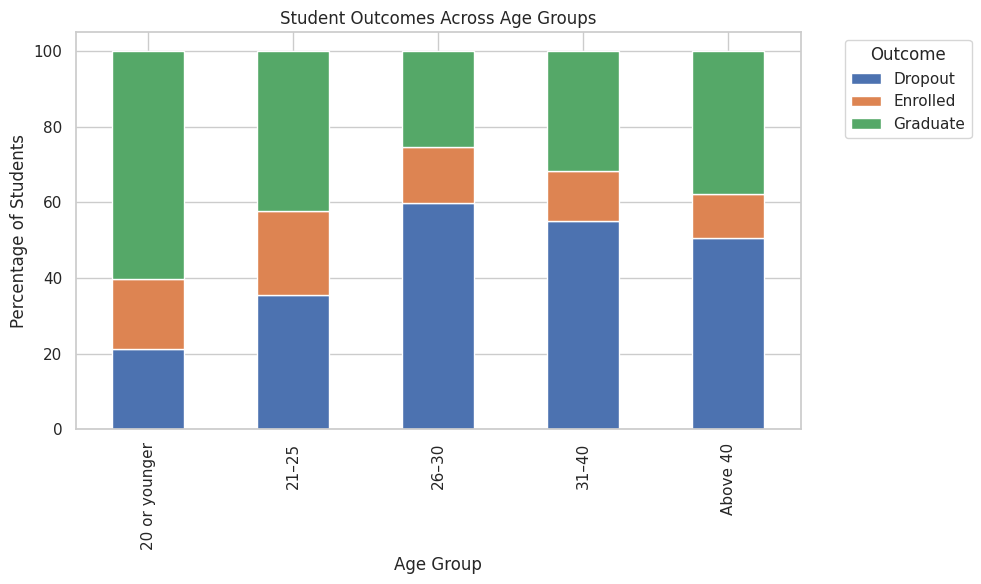

In [13]:

df["Age group"] = pd.cut(
    df["Age at enrollment"],
    bins=[0, 20, 25, 30, 40, float("inf")],
    labels=[
        "20 or younger",
        "21–25",
        "26–30",
        "31–40",
        "Above 40"
    ],
    right=True
)

age_outcome = pd.crosstab(
    df["Age group"],
    df["Target"],
    normalize="index"
) * 100

display(age_outcome.round(2))

age_outcome.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title("Student Outcomes Across Age Groups")
plt.xlabel("Age Group")
plt.ylabel("Percentage of Students")
plt.legend(title="Outcome", bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()


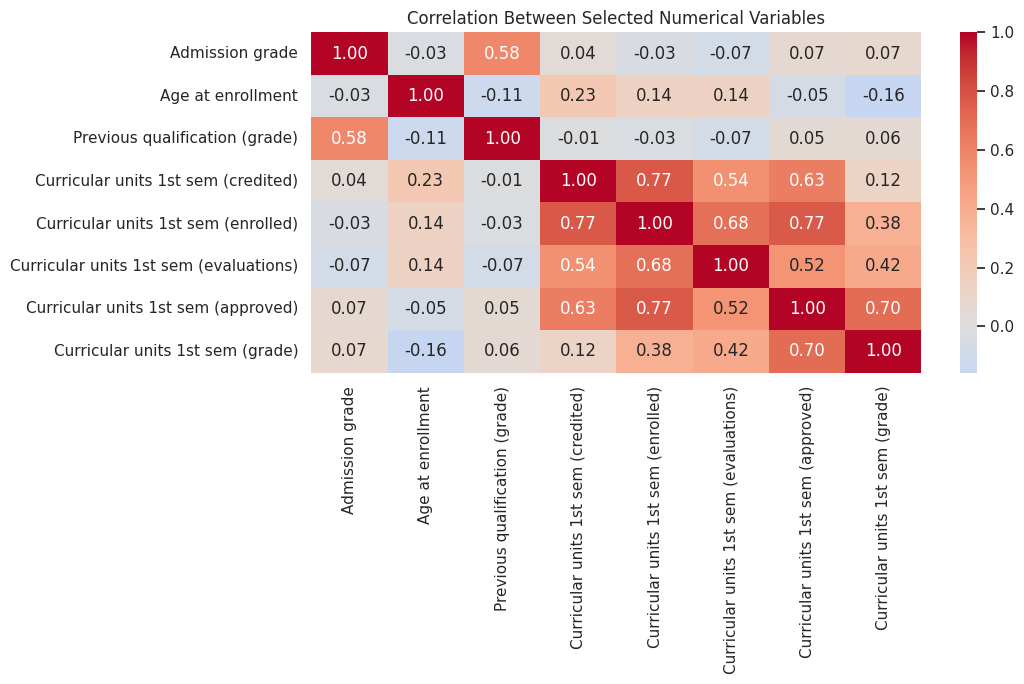

In [14]:

corr_cols = [
    "Admission grade",
    "Age at enrollment",
    "Previous qualification (grade)",
    "Curricular units 1st sem (credited)",
    "Curricular units 1st sem (enrolled)",
    "Curricular units 1st sem (evaluations)",
    "Curricular units 1st sem (approved)",
    "Curricular units 1st sem (grade)"
]

plt.figure(figsize=(11, 7))

sns.heatmap(
    df[corr_cols].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Correlation Between Selected Numerical Variables")
plt.tight_layout()
plt.show()


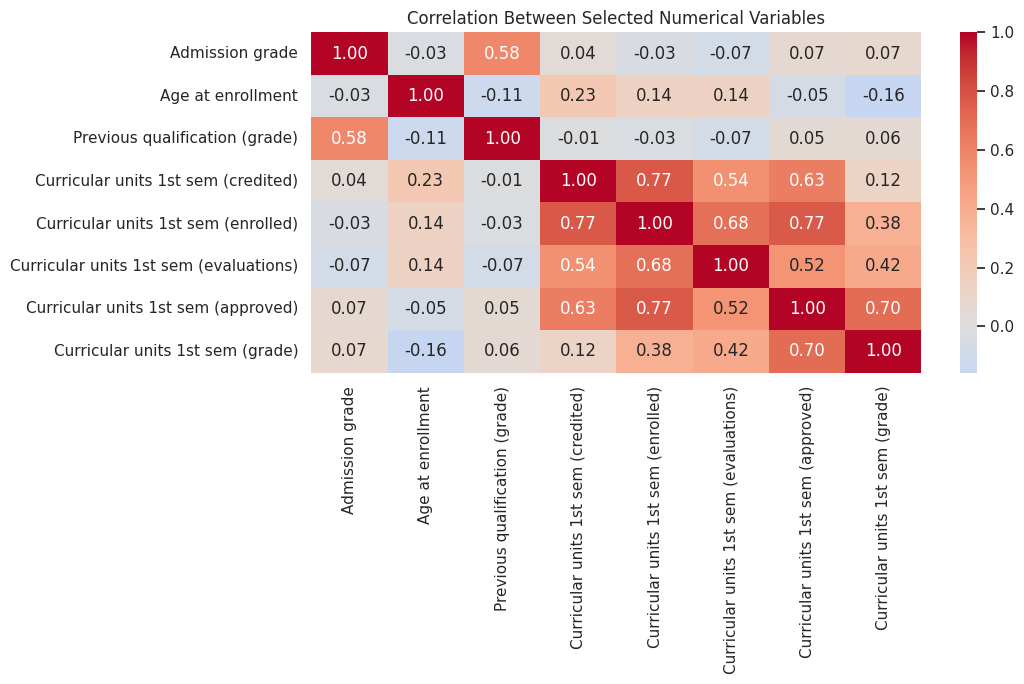

In [15]:

corr_cols = [
    "Admission grade",
    "Age at enrollment",
    "Previous qualification (grade)",
    "Curricular units 1st sem (credited)",
    "Curricular units 1st sem (enrolled)",
    "Curricular units 1st sem (evaluations)",
    "Curricular units 1st sem (approved)",
    "Curricular units 1st sem (grade)"
]

plt.figure(figsize=(11, 7))

sns.heatmap(
    df[corr_cols].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Correlation Between Selected Numerical Variables")
plt.tight_layout()
plt.show()


### EDA Observations

1. **Target distribution:** Graduates form the largest group, accounting for approximately 49.93% of students. Dropouts account for 32.12%, while enrolled students represent 17.95%.

2. **Admission grades:** Graduates have the highest mean admission grade (128.79), compared with enrolled students (125.53) and dropouts (124.96). The differences suggest an association between admission grades and student outcomes, although the group means are relatively close.

3. **First-semester performance:** Graduates have the highest mean first-semester grade (12.64) and the highest average number of approved curricular units (6.23). Dropouts have the lowest mean grade (7.26) and the lowest average number of approved units (2.55). Enrolled students fall between these groups for both measures.

4. **Age groups:** Students aged 20 or younger have a graduation percentage of approximately 60.29%. In the 26–30 age group, dropout accounts for approximately 59.79% of outcomes. This indicates differences in outcome distributions across age groups in this dataset.

5. **Correlation:** The correlation heatmap should be interpreted by identifying the strongest positive and negative correlations displayed. Correlation indicates association and does not establish causation.

Overall, the EDA suggests that first-semester academic performance and age are associated with student outcomes. These findings motivate further statistical testing and classification modelling.


### Hypothesis Testing

**Research question:** Do first-semester grades differ among students who Dropout, remain Enrolled, or Graduate?

- **Null hypothesis (H₀):** The grade distributions are the same across all three outcome groups.
- **Alternative hypothesis (H₁):** At least one outcome group has a different grade distribution.
- **Significance level:** α = 0.05.
- **Statistical test:** Kruskal–Wallis test.

A p-value below 0.05 provides evidence against the null hypothesis. A p-value of 0.05 or above means we fail to reject the null hypothesis.


In [17]:

from scipy.stats import kruskal, mannwhitneyu
grade_col = "Curricular units 1st sem (grade)"
groups = ["Dropout", "Enrolled", "Graduate"]

grade_groups = [
    df.loc[df["Target"] == group, grade_col].dropna()
    for group in groups
]

print("Group summaries:")

for group, values in zip(groups, grade_groups):
    print(
        f"{group}: n={len(values)}, "
        f"mean={values.mean():.2f}, "
        f"median={values.median():.2f}, "
        f"SD={values.std():.2f}"
    )

h_stat, p_value = kruskal(*grade_groups)

n_total = sum(len(values) for values in grade_groups)
k = len(grade_groups)

epsilon_squared = max(
    0,
    (h_stat - k + 1) / (n_total - k)
)

print("\nKruskal–Wallis H statistic:", round(h_stat, 4))
print("p-value:", p_value)
print("Approximate epsilon-squared:", round(epsilon_squared, 4))

if p_value < 0.05:
    print("\nDecision: Reject H₀.")
    print("At least one outcome group's grade distribution differs.")
else:
    print("\nDecision: Fail to reject H₀.")
    print("There is insufficient evidence of a difference.")


Group summaries:
Dropout: n=1421, mean=7.26, median=10.93, SD=6.03
Enrolled: n=794, mean=11.13, median=12.00, SD=3.68
Graduate: n=2209, mean=12.64, median=13.00, SD=2.70

Kruskal–Wallis H statistic: 1094.1865
p-value: 2.5143375393667276e-238
Approximate epsilon-squared: 0.247

Decision: Reject H₀.
At least one outcome group's grade distribution differs.


In [18]:
from itertools import combinations
from scipy.stats import mannwhitneyu

pairwise_results = []

for group_a, group_b in combinations(groups, 2):
    values_a = df.loc[df["Target"] == group_a, grade_col].dropna()
    values_b = df.loc[df["Target"] == group_b, grade_col].dropna()

    u_stat, p = mannwhitneyu(
        values_a,
        values_b,
        alternative="two-sided"
    )

    pairwise_results.append({
        "Comparison": f"{group_a} vs {group_b}",
        "U statistic": u_stat,
        "Raw p-value": p,
        "Bonferroni-adjusted p-value": min(p * 3, 1.0)
    })

pairwise_df = pd.DataFrame(pairwise_results)

pairwise_df["Significant at 0.05"] = (
    pairwise_df["Bonferroni-adjusted p-value"] < 0.05
)

display(pairwise_df.round(5))

,Comparison,U statistic,Raw p-value,Bonferroni-adjusted p-value,Significant at 0.05
0,Dropout vs Enrolled,368443.5,0.0,0.0,True
1,Dropout vs Graduate,600098.0,0.0,0.0,True
2,Enrolled vs Graduate,524677.0,0.0,0.0,True


### Interpretation of Hypothesis Test

The Kruskal–Wallis test was conducted to determine whether first-semester grades differ among students who Dropout, remain Enrolled, or Graduate. The test produced an H statistic of **1094.1865** and a p-value of **2.514 × 10⁻²³⁸**.

Since the p-value is far below the significance level of 0.05, the null hypothesis is rejected. There is strong statistical evidence that first-semester grade distributions differ across the three student outcome groups.

The approximate epsilon-squared effect size was **0.247**, indicating a meaningful difference in the grade distributions. The group means were 7.26 for Dropout, 11.13 for Enrolled, and 12.64 for Graduate.

The Bonferroni-adjusted pairwise Mann–Whitney U tests found statistically significant differences between all three pairs of outcome groups (adjusted p < 0.001). Graduates had the highest mean first-semester grades, while students who dropped out had the lowest.

These results demonstrate an association between first-semester academic performance and student outcome. They do not establish that grades alone cause a particular outcome.

In [19]:
feature_cols = binary_cols + categorical_cols + numerical_cols

X = df[feature_cols].copy()
y = df["Target"].copy()

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

print("\nTraining outcome proportions:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting outcome proportions:")
print(y_test.value_counts(normalize=True).round(3))

Training set: (3539, 30)
Testing set: (885, 30)

Training outcome proportions:
Target
Graduate    0.499
Dropout     0.321
Enrolled    0.179
Name: proportion, dtype: float64

Testing outcome proportions:
Target
Graduate    0.499
Dropout     0.321
Enrolled    0.180
Name: proportion, dtype: float64


In [20]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_cols),
        ("cat", categorical_transformer, binary_cols + categorical_cols)
    ]
)

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=3000,
        class_weight="balanced",
        random_state=42
    ))
])

print("Model pipeline created successfully.")

Model pipeline created successfully.


In [21]:
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Model training completed.")
print("Number of predictions:", len(y_pred))

Model training completed.
Number of predictions: 885


In [22]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

accuracy = accuracy_score(y_test, y_pred)

macro_precision = precision_score(
    y_test, y_pred, average="macro", zero_division=0
)

macro_recall = recall_score(
    y_test, y_pred, average="macro", zero_division=0
)

macro_f1 = f1_score(
    y_test, y_pred, average="macro", zero_division=0
)

print(f"Accuracy:        {accuracy:.4f}")
print(f"Macro precision: {macro_precision:.4f}")
print(f"Macro recall:    {macro_recall:.4f}")
print(f"Macro F1-score:  {macro_f1:.4f}")

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=["Dropout", "Enrolled", "Graduate"],
    zero_division=0
))

Accuracy:        0.6994
Macro precision: 0.6652
Macro recall:    0.6677
Macro F1-score:  0.6593

Classification report:
              precision    recall  f1-score   support

     Dropout       0.78      0.68      0.73       284
    Enrolled       0.38      0.56      0.46       159
    Graduate       0.83      0.76      0.79       442

    accuracy                           0.70       885
   macro avg       0.67      0.67      0.66       885
weighted avg       0.73      0.70      0.71       885



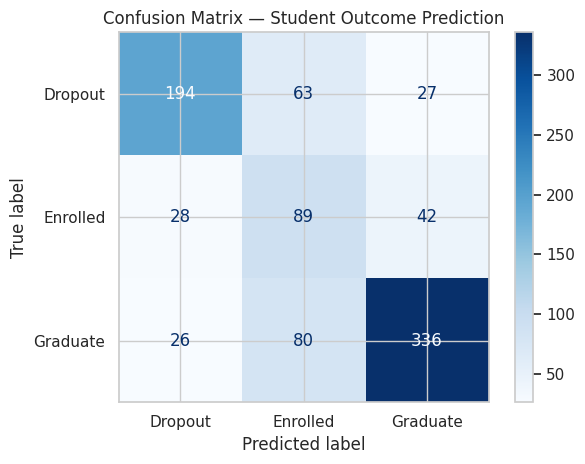

In [23]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

class_labels = ["Dropout", "Enrolled", "Graduate"]

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=class_labels
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_labels
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix — Student Outcome Prediction")
plt.tight_layout()
plt.show()

In [24]:
report_dict = classification_report(
    y_test,
    y_pred,
    labels=class_labels,
    output_dict=True,
    zero_division=0
)

class_metrics = pd.DataFrame(report_dict).T

display(
    class_metrics.loc[
        class_labels,
        ["precision", "recall", "f1-score", "support"]
    ].round(3)
)

,precision,recall,f1-score,support
Dropout,0.782,0.683,0.729,284.0
Enrolled,0.384,0.560,0.455,159.0
Graduate,0.830,0.760,0.793,442.0


In [25]:
fitted_preprocessor = model.named_steps["preprocessor"]
fitted_classifier = model.named_steps["classifier"]

feature_names = fitted_preprocessor.get_feature_names_out()
coefficients = fitted_classifier.coef_

for class_index, class_name in enumerate(fitted_classifier.classes_):
    class_coefficients = pd.DataFrame({
        "Feature": feature_names,
        "Coefficient": coefficients[class_index]
    })

    class_coefficients["Absolute coefficient"] = (
        class_coefficients["Coefficient"].abs()
    )

    print(f"\nLargest coefficients for {class_name}:")

    display(
        class_coefficients
        .sort_values("Absolute coefficient", ascending=False)
        .head(10)
        .round(4)
    )


Largest coefficients for Dropout:


,Feature,Coefficient,Absolute coefficient
7,num__Curricular units 1st sem (approved),-1.8195,1.8195
166,cat__Mother's occupation_0,1.4321,1.4321
208,cat__Father's occupation_90,1.2136,1.2136
193,cat__Mother's occupation_191,-1.2135,1.2135
54,cat__Course_171,-1.1366,1.1366
40,cat__Application mode_15,-1.0777,1.0777
21,cat__Tuition fees up to date_0,0.9780,0.9780
71,cat__Previous qualification_2,0.9093,0.9093
22,cat__Tuition fees up to date_1,-0.8942,0.8942
109,cat__Mother's qualification_4,-0.8795,0.8795



Largest coefficients for Enrolled:


,Feature,Coefficient,Absolute coefficient
166,cat__Mother's occupation_0,-1.6411,1.6411
177,cat__Mother's occupation_90,-1.3895,1.3895
160,cat__Father's qualification_39,1.2482,1.2482
208,cat__Father's occupation_90,-1.1162,1.1162
59,cat__Course_9119,1.0470,1.0470
39,cat__Application mode_10,-0.9112,0.9112
132,cat__Mother's qualification_43,0.8980,0.8980
112,cat__Mother's qualification_9,-0.8670,0.8670
194,cat__Mother's occupation_192,0.8217,0.8217
96,cat__Nacionality_25,0.8041,0.8041



Largest coefficients for Graduate:


,Feature,Coefficient,Absolute coefficient
7,num__Curricular units 1st sem (approved),2.1615,2.1615
40,cat__Application mode_15,1.3457,1.3457
54,cat__Course_171,1.3087,1.3087
5,num__Curricular units 1st sem (enrolled),-1.0681,1.0681
59,cat__Course_9119,-1.0174,1.0174
34,cat__Marital status_6,-0.9122,0.9122
160,cat__Father's qualification_39,-0.9053,0.9053
68,cat__Course_9853,-0.8436,0.8436
21,cat__Tuition fees up to date_0,-0.8401,0.8401
62,cat__Course_9238,0.7950,0.7950


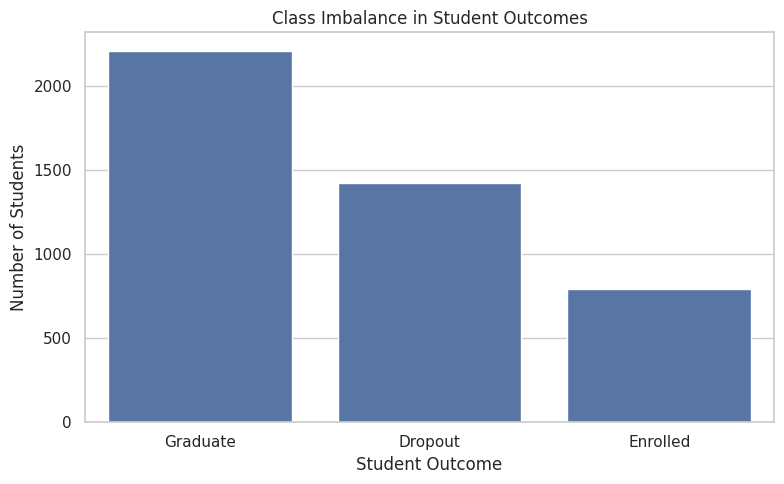

Class proportions (%):
Target
Graduate    49.93
Dropout     32.12
Enrolled    17.95
Name: count, dtype: float64

The model uses class_weight='balanced'. Macro metrics help assess performance across all classes.


In [26]:
class_distribution = df["Target"].value_counts()

plt.figure(figsize=(8, 5))

sns.barplot(
    x=class_distribution.index,
    y=class_distribution.values
)

plt.title("Class Imbalance in Student Outcomes")
plt.xlabel("Student Outcome")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

print("Class proportions (%):")
print(
    (class_distribution / class_distribution.sum() * 100)
    .round(2)
)

print(
    "\nThe model uses class_weight='balanced'. "
    "Macro metrics help assess performance across all classes."
)

In [27]:
results_summary = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Macro precision",
        "Macro recall",
        "Macro F1-score"
    ],
    "Score": [
        accuracy,
        macro_precision,
        macro_recall,
        macro_f1
    ]
})

display(results_summary.round(4))

,Metric,Score
0,Accuracy,0.6994
1,Macro precision,0.6652
2,Macro recall,0.6677
3,Macro F1-score,0.6593


## Recommendations

1. **Early academic support:** Use academic indicators to identify students who may benefit from tutoring, mentoring, or academic advising.
2. **Targeted student services:** Investigate whether financial or administrative barriers are associated with dropout patterns.
3. **Fair model evaluation:** Monitor precision, recall, and F1-score for each outcome instead of relying only on accuracy.
4. **Regular monitoring:** Evaluate the model on future student cohorts and check for changes in performance.
5. **Human oversight:** Use predictions to support student outreach, not to automatically restrict academic opportunities.

## Limitations

- The dataset may not represent every institution or future student cohort.
- Associations do not establish causation.
- Class imbalance may affect the less frequent outcome classes.
- Logistic regression may not capture complex nonlinear relationships.
- The model uses first-semester data, so it is intended for predictions made after that information becomes available.
- Student data must be protected, and potential bias should be assessed before real-world use.

## Conclusion

This case study uses exploratory data analysis, hypothesis testing, and multiclass logistic regression to investigate student outcomes. The analysis can reveal patterns associated with dropout and academic success. However, predictions should be validated on new data and used responsibly alongside human judgment.

In [28]:
display(
    class_metrics.loc[
        ["Dropout", "Enrolled", "Graduate"],
        ["precision", "recall", "f1-score", "support"]
    ].round(3)
)

,precision,recall,f1-score,support
Dropout,0.782,0.683,0.729,284.0
Enrolled,0.384,0.560,0.455,159.0
Graduate,0.830,0.760,0.793,442.0


## Part E: Interpretation, Limitations and Recommendations

### Interpretation of Results

The exploratory analysis indicates that student outcomes are associated with academic performance and age. Graduates had a higher average first-semester grade (12.64) than enrolled students (11.13) and dropout students (7.26). The Kruskal–Wallis test found statistically significant differences in first-semester grade distributions across the three outcome groups (H = 1094.1865, p < 0.001).

The Logistic Regression model achieved 69.94% accuracy and a macro F1-score of 65.93%. It performed best for Graduate students (F1-score = 0.79), followed by Dropout students (0.73). Performance was weakest for Enrolled students (0.46), indicating difficulty distinguishing this class from the other outcomes.

### Limitations

1. The dataset contains more Graduate students than Enrolled students, so class imbalance may affect predictive performance.
2. Logistic Regression may not capture complex, nonlinear relationships between student characteristics and outcomes.
3. The model was evaluated using a single stratified train-test split. Performance may vary across different splits or populations.
4. The analysis identifies associations and predictive patterns; it does not establish causation.
5. Predictions may be affected by unobserved factors such as personal circumstances, financial difficulties, or access to academic support.
6. Some features, including demographic and financial indicators, may introduce fairness or privacy concerns if used without appropriate safeguards.

### Recommendations

1. **Early academic support:** Monitor first-semester grades and approved curricular units to identify students who may benefit from tutoring or academic guidance.
2. **Support for at-risk students:** Offer counselling, financial guidance, and additional academic resources based on individual needs rather than relying solely on model predictions.
3. **Model improvement:** Compare Logistic Regression with Decision Tree, Random Forest, and other suitable classifiers using consistent evaluation methods.
4. **Improve Enrolled-class predictions:** Investigate the misclassifications involving Enrolled students and evaluate class-specific performance before selecting a final model.
5. **Responsible use:** Protect student data, assess model fairness across relevant groups, explain predictions where possible, and keep human review in the decision-making process.

### Conclusion

This case study used exploratory data analysis, non-parametric hypothesis testing, and multiclass Logistic Regression to study student outcomes. The results indicate a strong association between first-semester academic performance and outcome category. The baseline model achieved 69.94% accuracy, but its weaker performance for Enrolled students shows that further evaluation and improvement are needed. The model should be treated as a decision-support tool, not as a definitive judgment about any student.